# 06 What-if analysis

**Question.** How does the IP's result change when its stability weights (`mu` per moved prompt,
`F` per rebalance), its capacity limits (`U`, `K_T`) and the weight of the judge (`gamma`) change?
Which settings trade fit against disruption best?

Each setting re-runs the whole session with the IP (offline stand-in judge, draft gold labels).
The single-step flip keeps one step's state fixed and re-solves only that step.

In [1]:
import sys
from itertools import product
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from forest import config, viz
from forest.config import with_overrides
from forest.io import SESSION_IDS, load_gold, load_sessions
from forest.ip import ACTION_NAMES, place
from forest.metrics import Scorer, summarize
from forest.simulate import make_context, run, trace_ip

viz.style()
cfg = config.load()
ctx = make_context(cfg)
P0 = ctx.params
scorer = Scorer(ctx.emb, cfg)
sessions = load_sessions()
golds = {sid: load_gold(sid) for sid in SESSION_IDS}
FIG, MET = Path(cfg["paths"]["figures"]), Path(cfg["paths"]["metrics"])
GRID = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]  # log-spaced

def run_ip(sid, params, c=ctx):
    df, _ = run("ip", sessions[sid], c, params, golds[sid], scorer=scorer, guard=False)
    return summarize(df)

## Sweep over `mu` x `F` on `s1_focused`

Restricted license - for non-production use only - expires 2028-11-29


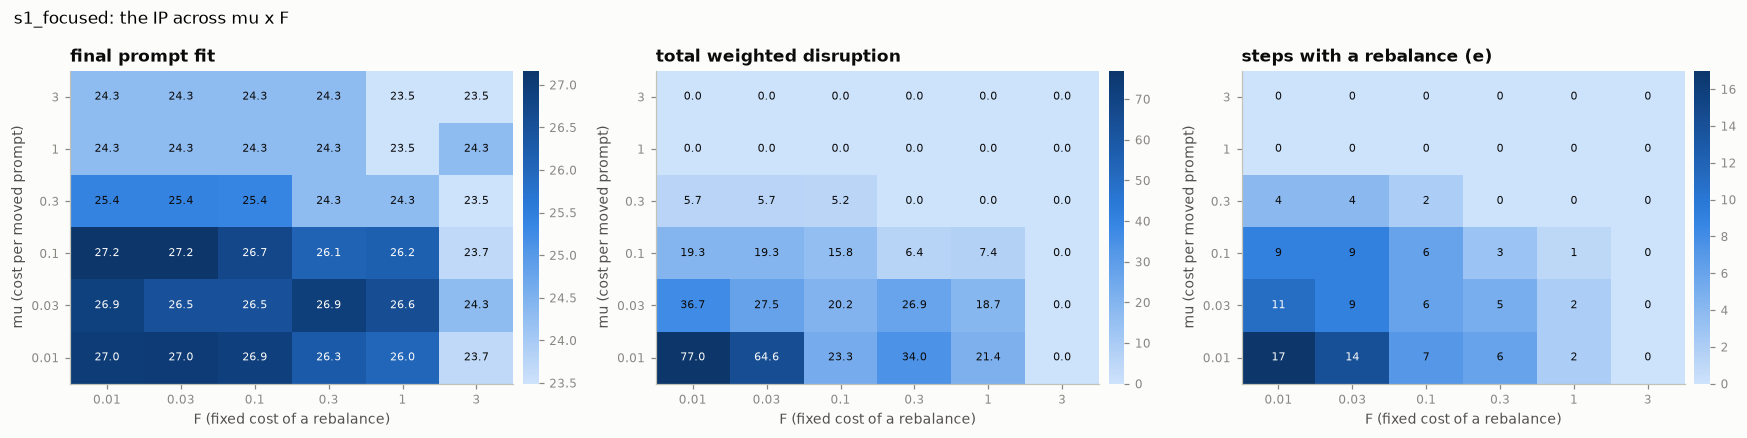

rebalances


F,0.01,0.03,0.10,0.30,1.00,3.00
mu,,,,,,
0.01,17,14,7,6,2,0
0.03,11,9,6,5,2,0
0.10,9,9,6,3,1,0
0.30,4,4,2,0,0,0
1.00,0,0,0,0,0,0
3.00,0,0,0,0,0,0


final_fit


F,0.01,0.03,0.10,0.30,1.00,3.00
mu,,,,,,
0.01,27.0,27.0,26.9,26.3,26.0,23.7
0.03,26.9,26.5,26.5,26.9,26.6,24.3
0.10,27.2,27.2,26.7,26.1,26.2,23.7
0.30,25.4,25.4,25.4,24.3,24.3,23.5
1.00,24.3,24.3,24.3,24.3,23.5,24.3
3.00,24.3,24.3,24.3,24.3,23.5,23.5


disruption_w


F,0.01,0.03,0.10,0.30,1.00,3.00
mu,,,,,,
0.01,77.0,64.6,23.3,34.0,21.4,0.0
0.03,36.7,27.5,20.2,26.9,18.7,0.0
0.10,19.3,19.3,15.8,6.4,7.4,0.0
0.30,5.7,5.7,5.2,0.0,0.0,0.0
1.00,0.0,0.0,0.0,0.0,0.0,0.0
3.00,0.0,0.0,0.0,0.0,0.0,0.0


In [2]:
rows = []
for mu, F in product(GRID, GRID):
    s = run_ip("s1_focused", P0.replace(mu=mu, F=F))
    rows.append({"mu": mu, "F": F, "final_fit": s["final_fit"], "disruption_w": s["disruption_w"],
                 "rebalances": int(s["actions"].split("e:")[1].split()[0]) if "e:" in s["actions"] else 0,
                 "moved_prompts": s["moved_prompts"], "topics": s["topics"], "ari_topic": s["ari_topic"]})
sweep = pd.DataFrame(rows)
sweep.to_csv(MET / "06_sweep_mu_F_s1.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (col, title, fmt) in zip(axes, [("final_fit", "final prompt fit", "{:.1f}"),
                                         ("disruption_w", "total weighted disruption", "{:.1f}"),
                                         ("rebalances", "steps with a rebalance (e)", "{:.0f}")]):
    viz.heatmap(sweep.pivot(index="mu", columns="F", values=col), ax, title=title, fmt=fmt,
                xlabel="F (fixed cost of a rebalance)", ylabel="mu (cost per moved prompt)")
fig.suptitle("s1_focused: the IP across mu x F", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
viz.save(fig, FIG / "06_sweep_mu_F_heatmaps.png")
plt.show()
for col in ["rebalances", "final_fit", "disruption_w"]:
    print(col)
    display(sweep.pivot(index="mu", columns="F", values=col).round(1))

,mu,F,final_fit,disruption_w,rebalances,topics
11,0.03,3.00,24.301612,0.000000,0,16
21,0.30,0.30,24.301612,0.000000,0,16
22,0.30,1.00,24.301612,0.000000,0,16
24,1.00,0.01,24.301612,0.000000,0,16
25,1.00,0.03,24.301612,0.000000,0,16
26,1.00,0.10,24.301612,0.000000,0,16
27,1.00,0.30,24.301612,0.000000,0,16
29,1.00,3.00,24.301612,0.000000,0,16
30,3.00,0.01,24.301612,0.000000,0,16
31,3.00,0.03,24.301612,0.000000,0,16


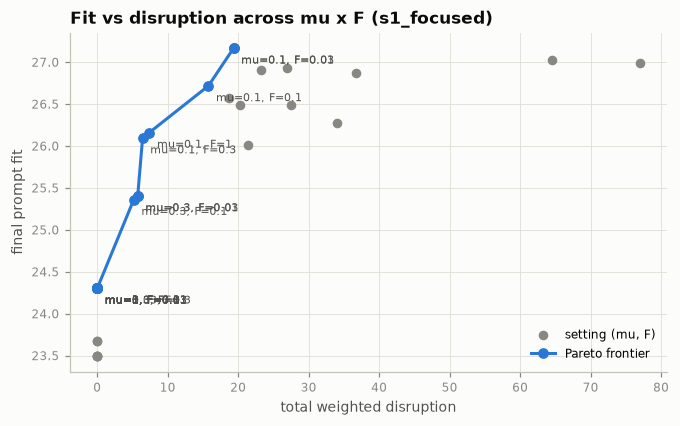

In [3]:
pts = list(zip(sweep["disruption_w"], sweep["final_fit"]))
front = viz.pareto(pts)
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(sweep["disruption_w"], sweep["final_fit"], s=28, color=viz.MUTED, label="setting (mu, F)")
fr = sweep.iloc[front]
ax.plot(fr["disruption_w"], fr["final_fit"], color=viz.SLOTS[0], marker="o", ms=6, label="Pareto frontier")
for _, r in fr.iterrows():
    ax.annotate(f"mu={r['mu']:g}, F={r['F']:g}", (r["disruption_w"], r["final_fit"]), xytext=(5, -10),
                textcoords="offset points", fontsize=7, color=viz.TEXT_2)
d = sweep[(sweep["mu"] == P0.mu) & (sweep["F"] == P0.F)]
if len(d):
    ax.scatter(d["disruption_w"], d["final_fit"], s=90, facecolor="none", edgecolor=viz.SLOTS[1], linewidth=2,
               label=f"config (mu={P0.mu}, F={P0.F})")
ax.set_xlabel("total weighted disruption")
ax.set_ylabel("final prompt fit")
ax.set_title("Fit vs disruption across mu x F (s1_focused)")
ax.legend(loc="lower right")
viz.save(fig, FIG / "06_pareto.png")
fr[["mu", "F", "final_fit", "disruption_w", "rebalances", "topics"]]

## Single-step flip
The IP trajectory with the configured weights is replayed. Every step's input is re-solved over
the `mu` x `F` grid with the state held fixed, and the step whose action changes the most is
shown: which action wins where.

step 13: 'How do I do gradient checking with finite differences? What epsilon should I pick?'
actions over the grid: {'b': 'new branch', 'e': 'rebalance'}


F,0.01,0.03,0.10,0.30,1.00,3.00
mu,,,,,,
0.01,e,e,e,e,b,b
0.03,e,e,e,e,b,b
0.10,e,e,e,e,b,b
0.30,e,e,b,b,b,b
1.00,b,b,b,b,b,b
3.00,b,b,b,b,b,b


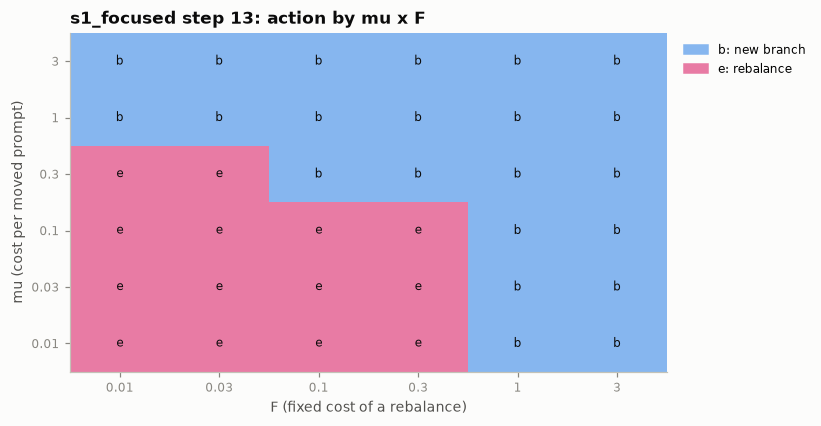

In [4]:
trace = trace_ip(sessions["s1_focused"], ctx)
best, best_tab = None, None
for t in trace[2:]:
    acts = {(mu, F): place(t["input"], P0.replace(mu=mu, F=F)).action for mu, F in product(GRID, GRID)}
    distinct = set(acts.values())
    score = (len(distinct), "e" in distinct, "b" in distinct)
    if best is None or score > best[0]:
        best = (score, t)
        best_tab = acts
t = best[1]
flip = pd.DataFrame([{"mu": mu, "F": F, "action": a} for (mu, F), a in best_tab.items()]).pivot(index="mu", columns="F", values="action")
print(f"step {t['prompt'].step}: {t['prompt'].text!r}")
print("actions over the grid:", {a: ACTION_NAMES[a] for a in sorted(set(best_tab.values()))})
fig, ax = plt.subplots(figsize=(7, 4))
viz.action_heatmap(flip, ax, title=f"s1_focused step {t['prompt'].step}: action by mu x F",
                   xlabel="F (fixed cost of a rebalance)", ylabel="mu (cost per moved prompt)")
viz.save(fig, FIG / "06_single_step_flip.png")
flip

## Capacity: `U` (prompts per topic) and `K_T` (trees per group)
`s2_mixed` has several groups, so `K_T` can bind there. `s1_focused` is shown for `U`.

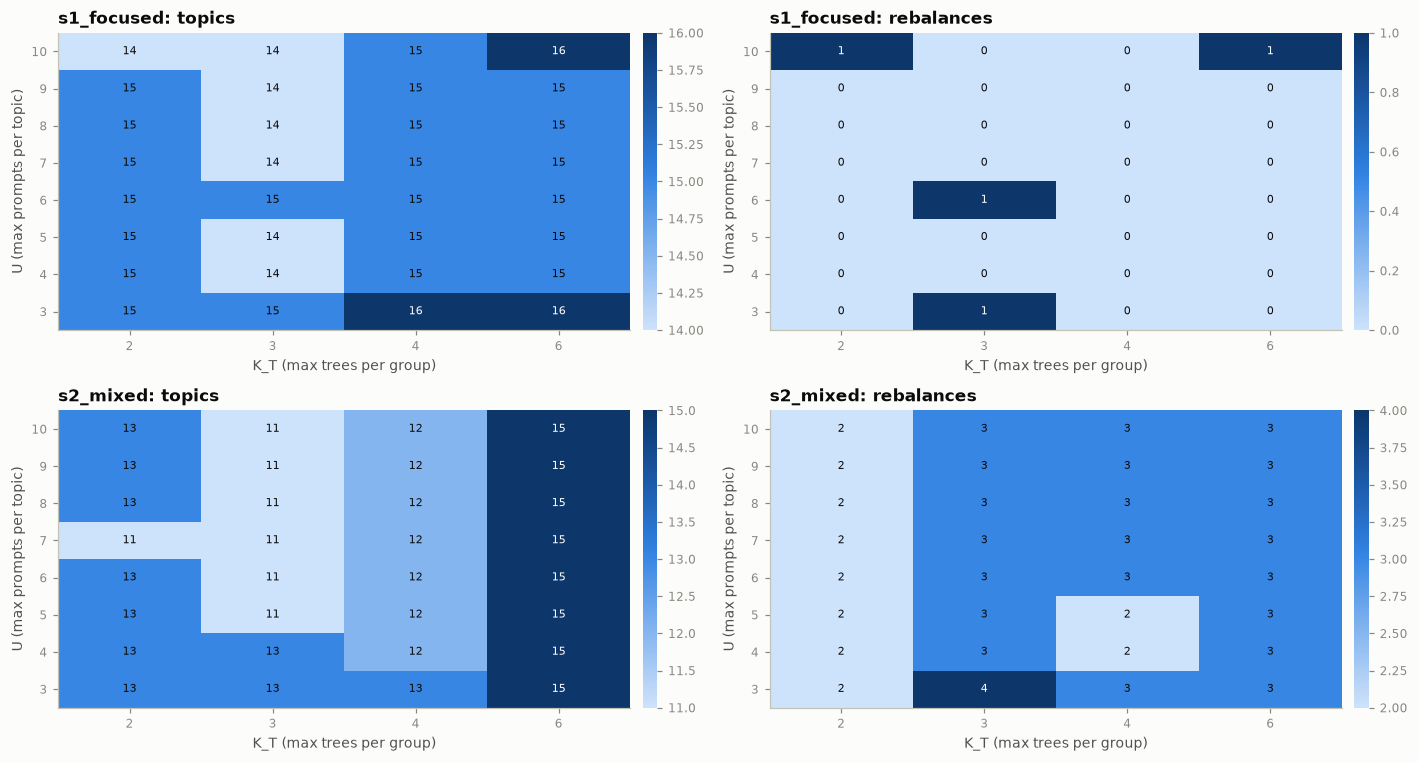

s1_focused trees


K_T,2,3,4,6
U,,,,
3,2,3,4,6
4,2,3,4,6
5,2,3,4,6
6,2,3,4,6
7,2,3,4,6
8,2,3,4,6
9,2,3,4,6
10,2,3,4,6


s1_focused topics


K_T,2,3,4,6
U,,,,
3,15,15,16,16
4,15,14,15,15
5,15,14,15,15
6,15,15,15,15
7,15,14,15,15
8,15,14,15,15
9,15,14,15,15
10,14,14,15,16


s1_focused rebalances


K_T,2,3,4,6
U,,,,
3,0,1,0,0
4,0,0,0,0
5,0,0,0,0
6,0,1,0,0
7,0,0,0,0
8,0,0,0,0
9,0,0,0,0
10,1,0,0,1


... (2 outputs left out)

s2_mixed topics


K_T,2,3,4,6
U,,,,
3,13,13,13,15
4,13,13,12,15
5,13,11,12,15
6,13,11,12,15
7,11,11,12,15
8,13,11,12,15
9,13,11,12,15
10,13,11,12,15


s2_mixed rebalances


K_T,2,3,4,6
U,,,,
3,2,4,3,3
4,2,3,2,3
5,2,3,2,3
6,2,3,3,3
7,2,3,3,3
8,2,3,3,3
9,2,3,3,3
10,2,3,3,3


In [5]:
rows = []
for sid in ["s1_focused", "s2_mixed"]:
    for U, K_T in product(range(3, 11), [2, 3, 4, 6]):
        s = run_ip(sid, P0.replace(U=U, K_T=K_T))
        rows.append({"session": sid, "U": U, "K_T": K_T, "topics": s["topics"], "trees": s["trees"],
                     "rebalances": int(s["actions"].split("e:")[1].split()[0]) if "e:" in s["actions"] else 0,
                     "over_U": s["over_U"], "final_fit": s["final_fit"]})
cap = pd.DataFrame(rows)
cap.to_csv(MET / "06_capacity.csv", index=False)
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for i, sid in enumerate(["s1_focused", "s2_mixed"]):
    d = cap[cap["session"] == sid]
    viz.heatmap(d.pivot(index="U", columns="K_T", values="topics"), axes[i, 0], title=f"{sid}: topics", fmt="{:.0f}",
                xlabel="K_T (max trees per group)", ylabel="U (max prompts per topic)")
    viz.heatmap(d.pivot(index="U", columns="K_T", values="rebalances"), axes[i, 1], title=f"{sid}: rebalances", fmt="{:.0f}",
                xlabel="K_T (max trees per group)", ylabel="U (max prompts per topic)")
fig.tight_layout()
viz.save(fig, FIG / "06_capacity.png")
plt.show()
for sid in ["s1_focused", "s2_mixed"]:
    for col in ["trees", "topics", "rebalances"]:
        print(sid, col)
        display(cap[cap["session"] == sid].pivot(index="U", columns="K_T", values=col))

## Judge weight `gamma`
`gamma = 0`: embeddings only; `0.5`: mixed; `1`: judge only (for rated pairs). With the offline
stand-in, the "judge" is itself a coarsened cosine, so this mainly tests the plumbing. Re-run it
with a live judge.

In [6]:
rows = []
for gamma in [0.0, 0.5, 0.7, 1.0]:
    c = make_context(with_overrides(cfg, scores={"gamma": gamma}), emb=ctx.emb, judge=ctx.judge)
    for sid in SESSION_IDS:
        s = run_ip(sid, P0, c)
        rows.append({"gamma": gamma, "session": sid, "final_fit": s["final_fit"], "topics": s["topics"],
                     "disruption_w": s["disruption_w"], "ari_topic": s["ari_topic"], "ari_group": s["ari_group"]})
gam = pd.DataFrame(rows)
gam.to_csv(MET / "06_gamma.csv", index=False)
gam.pivot(index="gamma", columns="session", values=["final_fit", "topics", "ari_topic"]).round(2)

final_fit                       topics                    ari_topic  \
session s1_focused s2_mixed s3_drift s1_focused s2_mixed s3_drift s1_focused   
gamma                                                                          
0.0          23.81    24.38    17.47       14.0     16.0     10.0       0.31   
0.5          23.37    20.05    14.04       14.0     13.0      8.0       0.27   
0.7          23.49    19.03    16.23       15.0     12.0     10.0       0.26   
1.0          26.11    20.32    19.72       14.0     13.0     13.0       0.23   

                           
session s2_mixed s3_drift  
gamma                      
0.0         0.45     0.19  
0.5         0.35     0.16  
0.7         0.32     0.06  
1.0         0.44     0.26

## `lam_G`: the cost of a new group (see 04 for the bound)

In [7]:
rows = []
for lam_G in [0.0, 0.25, 0.5, 0.75, 1.0]:
    s = run_ip("s2_mixed", P0.replace(lam_G=lam_G))
    rows.append({"lam_G": lam_G, "groups": s["groups"], "trees": s["trees"], "topics": s["topics"],
                 "ari_group": s["ari_group"], "final_fit": s["final_fit"]})
pd.DataFrame(rows).round(3)

,lam_G,groups,trees,topics,ari_group,final_fit
0,0.00,3,7,15,0.103,22.740
1,0.25,3,7,15,0.103,22.740
2,0.50,2,5,12,0.010,19.032
3,0.75,1,4,12,0.000,19.235
4,1.00,1,4,12,0.000,19.235


## Findings

- **`mu` x `F`:** on `s1_focused`, rebalances fall steadily from 17 steps (`mu = F = 0.01`) to
  none once `mu >= 1` or `F = 3`. Final fit falls from 27.0 to 23.5, and weighted disruption
  from 77 to 0. Fit ranges from 23.5 to 27.2 over the whole grid, so the stability weights cost
  up to about 13 % of fit.
- **Operating point:** the configured weights (`mu = 0.3`, `F = 0.5`) sit at the stable end:
  no rebalance on s1 (fit 23.5 in 05). `mu = 0.3, F = 0.1` (fit 25.4, 2 rebalances, disruption 5.2)
  and `mu = 0.1, F = 0.3` (26.1, 3 rebalances, 6.4) buy about 2 to 2.6 fit points for 2 to 3
  rebalances. The group picks the point to report.
- **Single-step flip** (s1 step 13, "gradient checking with finite differences"): the IP opens a
  new branch (b) when `mu >= 1` or `F >= 1`, and rebalances (e) for `mu <= 0.1` with `F <= 0.3`
  (and at `mu = 0.3` with `F <= 0.03`), moving earlier prompts into the new subtopic. Adding to an
  existing topic (a) never wins at this step, so this is a two-way flip, not the three-way
  (a)/(b)/(e) case the plan hoped for. No step of s1 had all three with the stand-in judge.
- **Capacity:** with one group (s1), the number of trees always equals `K_T`, so `K_T` binds.
  `U` hardly changes the topic count (14 to 16), because with the stand-in judge topics rarely
  reach `U` before a new one opens. `lam_G` decides the number of groups on s2: 3 groups at
  `lam_G <= 0.25`, 2 at 0.5, 1 from 0.75.
- **`gamma`:** no consistent direction with the stand-in, whose "judge" is a coarsened cosine.
  Re-run with a live judge. *The group's interpretation goes here.*